<a href="https://colab.research.google.com/github/Willortizp75/Willortizp75/blob/main/Tarea1_ML_Modelos_Regresion_Python_WOP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ESPY G6 - Curso: 3 ML Modelos de Regresión con Python**
# Tarea 1: **Predicción de la resistencia del concreto mediante modelos lineales**
> ## Autor: ***Wilfrido Ortiz Prieto***

## **Contexto del problema**
Una empresa dedicada a la producción de concreto desea mejorar su capacidad para estimar la resistencia de sus productos.

Actualmente, la empresa dispone de información histórica sobre la composición de diferentes mezclas de concreto, incluyendo la cantidad de cemento, agua, agregados, aditivos y el tiempo de curado.

La empresa desea aprovechar estos datos para desarrollar modelos predictivos que permitan estimar la resistencia del concreto en megapascales (MPa).

Para ello, se solicita desarrollar un análisis utilizando las técnicas de regresión lineal estudiadas en clase.

## **Objetivo de la tarea**

Construir y comparar diferentes modelos de regresión lineal que permitan estimar la resistencia del concreto a partir de las características de su composición.

## **Actividades por desarrollar**

## **Parte 1. Carga y exploración de datos (20 puntos)**

1. Cargar el dataset proporcionado en Python.
2. Visualizar los primeros registros.
3. Identificar las dimensiones del dataset.
4. Verificar si existen valores faltantes.
5. Obtener estadísticas descriptivas de las variables.
6. Identificar cuál es la variable dependiente y cuáles son las variables independientes.  

**Pregunta de análisis:** ¿Qué información contiene el dataset y qué queremos predecir?

In [1]:
# Cargar librerias
import sklearn

# Tratamiento de Datos
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

# Preprocesamiento y Modelo
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler

# Configuracion de nuestro visuales
plt.rcParams['image.cmap'] = 'bwr'
plt.rcParams['savefig.bbox'] = 'tight'
style.use('ggplot') or plt.style.use('ggplot')

# Ignorar las advertencias de paquetes y sus actualizaciones
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Carga de archivo de datos

datos = pd.read_csv('/content/drive/MyDrive/ML Regresion con Python/Dataset/Concrete_Data.csv')
datos.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
datos.shape

(1030, 9)

In [5]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [6]:
datos.isnull().sum()

,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,0


In [7]:
datos.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
# Variables Dependientes e Independientes

variables_independientes = list(datos.columns[:-1])
variable_dependiente = datos.columns[-1]

print("Variables Independientes (X):")
for var in variables_independientes:
    print(f" - {var}")

print("\nVariable Dependiente (Y):")  # \n es para salto de línea
print(f" - {variable_dependiente}")

Variables Independientes (X):
 - Cement
 - Blast Furnace Slag
 - Fly Ash
 - Water
 - Superplasticizer
 - Coarse Aggregate
 - Fine Aggregate
 - Age

Variable Dependiente (Y):
 - Concrete compressive strength


**Información que contiene el dataset:**
> Contiene las cantidades de los componentes físicos para preparar el concreto en kilogramos por metro cúbico, el tiempo de maduración, y la resistencia final medida tras ese periodo.

**Qué se trata de predecir:**
> Se trata de predecir la Resistencia a la Compresión del Concreto, utilizando como características de entrada la combinación de sus ingredientes y la edad de la mezcla.


## **Parte 2. Análisis de relaciones entre variables (20 puntos)**

1. Construir una matriz de correlación.
2. Representar gráficamente las correlaciones mediante un mapa de calor.
3. Identificar las variables que tienen mayor correlación positiva y negativa con la resistencia del concreto.
4. Identificar si existen variables independientes altamente correlacionadas entre sí.

**Pregunta de análisis:** ¿Cuáles variables parecen estar más relacionadas con la resistencia del concreto? ¿Existen posibles problemas de multicolinealidad?

In [9]:
# Correlación entre variables

corr = datos.corr(numeric_only= True).round(2)

print("Matriz de correlación:")
corr

Matriz de correlación:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
Cement,1.00,-0.28,-0.40,-0.08,0.09,-0.11,-0.22,0.08,0.50
Blast Furnace Slag,-0.28,1.00,-0.32,0.11,0.04,-0.28,-0.28,-0.04,0.13
Fly Ash,-0.40,-0.32,1.00,-0.26,0.38,-0.01,0.08,-0.15,-0.11
Water,-0.08,0.11,-0.26,1.00,-0.66,-0.18,-0.45,0.28,-0.29
Superplasticizer,0.09,0.04,0.38,-0.66,1.00,-0.27,0.22,-0.19,0.37
Coarse Aggregate,-0.11,-0.28,-0.01,-0.18,-0.27,1.00,-0.18,-0.00,-0.16
Fine Aggregate,-0.22,-0.28,0.08,-0.45,0.22,-0.18,1.00,-0.16,-0.17
Age,0.08,-0.04,-0.15,0.28,-0.19,-0.00,-0.16,1.00,0.33
Concrete compressive strength,0.50,0.13,-0.11,-0.29,0.37,-0.16,-0.17,0.33,1.00


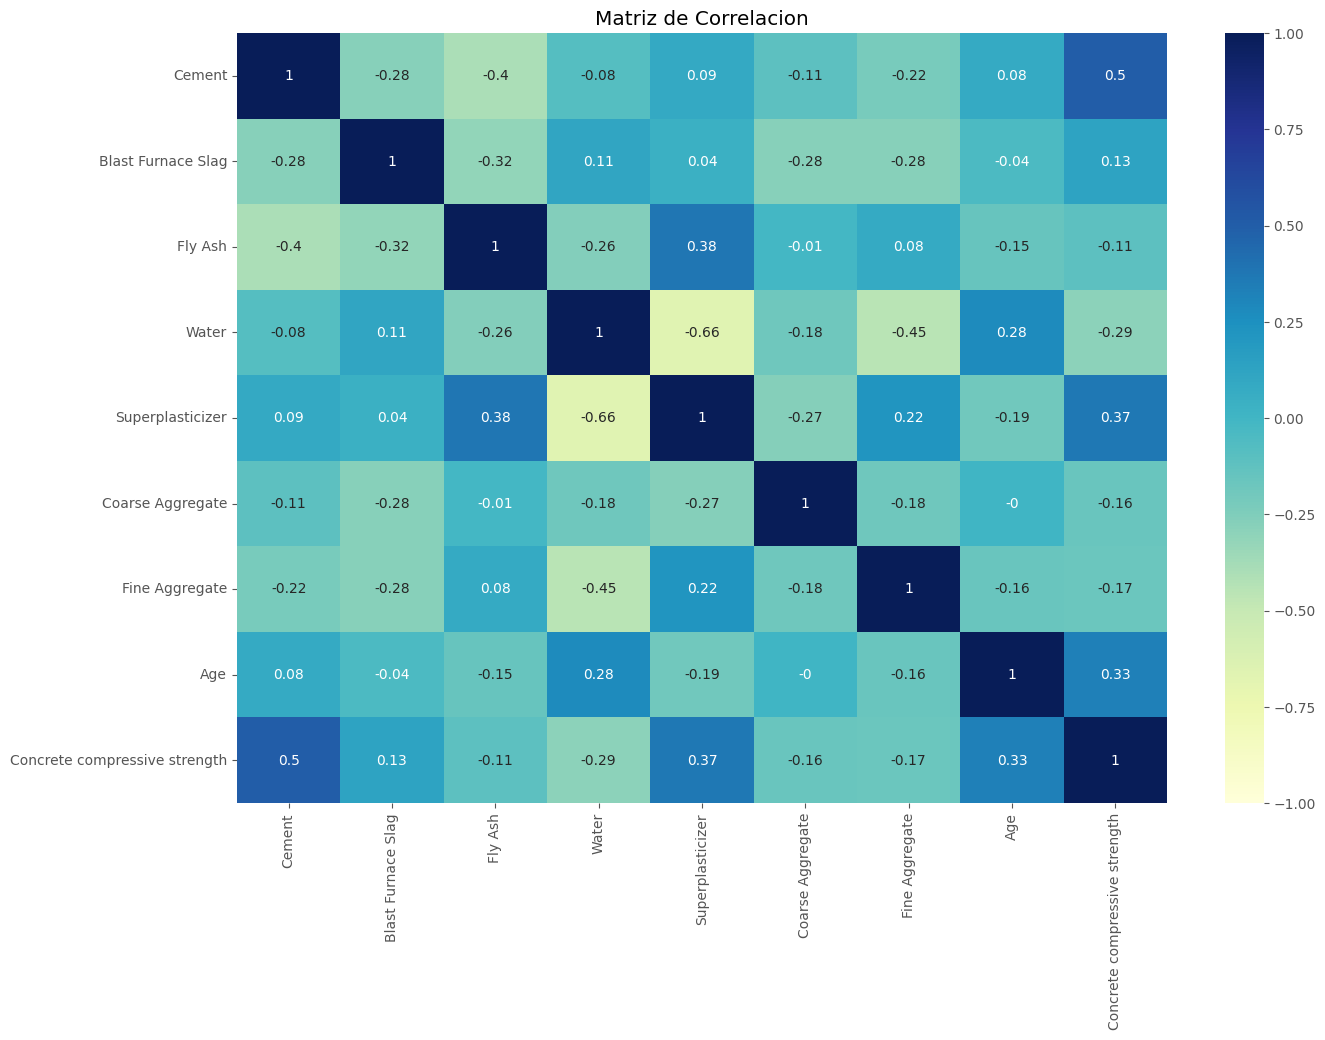

In [10]:
# Mapa de Calor de la Correlación

fig, ax  =  plt.subplots(figsize = (15,10))
sns.heatmap(corr, annot = True,cmap = 'YlGnBu', ax = ax, vmax = 1, vmin = -1)
plt.title('Matriz de Correlacion')
plt.show()

In [11]:
# Variables con mayor correlación positiva y negativa con la resistencia del concreto

corr_resist_concr = corr['Concrete compressive strength'].drop('Concrete compressive strength')
corr_positiva_max = corr_resist_concr.idxmax()
corr_negativa_max = corr_resist_concr.idxmin()


print(f"Variable con mayor correlación positiva: '{corr_positiva_max}' ({corr_resist_concr[corr_positiva_max]:.3f})")
print(f"Variable con mayor correlación negativa: '{corr_negativa_max}' ({corr_resist_concr[corr_negativa_max]:.3f})")


Variable con mayor correlación positiva: 'Cement' (0.500)
Variable con mayor correlación negativa: 'Water' (-0.290)


In [12]:
# Variables independientes altamente correlacionadas entre sí

print("Variables independientes altamente correlacionadas entre sí")

features = datos.columns[:-1]
for i in range(len(features)):
    for j in range(i+1, len(features)):
        coef = corr.loc[features[i], features[j]]
        if abs(coef) > 0.5:
            print(f" - '{features[i]}' y '{features[j]}': {coef:.3f}")


Variables independientes altamente correlacionadas entre sí
 - 'Water' y 'Superplasticizer': -0.660


**1. ¿Cuáles variables parecen estar más relacionadas con la resistencia del concreto?**
* **Relación positiva fuerte:** El cemento (Cement) con una correlación de 0.50 y la edad (Age) con 0.33 son las variables más positivamente correlacionadas con la resistencia.  
También el superplastificante (Superplasticizer) muestra una relación positiva considerable (~0.37).
* **Relación negativa notable:** El agua (Water) tiene una correlación negativa de ~-0.29, lo que sugiere que mayores cantidades de agua (manteniendo otros factores constantes) tienden a reducir la resistencia del concreto.

**2. ¿Existen posibles problemas de multicolinealidad?**
* Sí, existen relaciones moderadas a fuertes entre algunas variables independientes que merecen atención:
  * Superplastificante y Agua tienen una correlación negativa de -0.66. Esto tiene lógica física, ya que el superplastificante se usa para reducir la necesidad de agua en la mezcla.
  * Superplastificante y Ceniza Volante tienen una correlación positiva de 0.38.
  * Agregado Fino y Agua tienen una correlación negativa de -0.45.
* Aunque ninguna correlación entre variables independientes supera el umbral crítico estricto tradicional (generalmente $|r| > 0.8$), la relación entre el agua y el superplastificante es notablemente fuerte (-0.66). Esto podría generar cierta inestabilidad o redundancia en un modelo de regresión lineal simple (multicolinealidad moderada).

## **Parte 3. Construcción de modelos (30 puntos)**

Dividir los datos utilizando:
* 80% para entrenamiento.
* 20% para prueba.
* random_state = 42.

Construir los siguientes modelos:

**Modelo 1. Regresión Lineal (OLS)**

Entrenar un modelo mediante mínimos cuadrados ordinarios para predecir la resistencia del concreto.

**Modelo 2. Regresión Ridge**

Entrenar un modelo con regularización Ridge utilizando alpha = 1.0.

**Modelo 3. Regresión Lasso**

Entrenar un modelo con regularización Lasso utilizando alpha = 1.0.

Para Ridge y Lasso, realizar el escalamiento de las variables predictoras, ajustándolo exclusivamente con los datos de entrenamiento.

No es necesario realizar búsqueda de hiperparámetros ni validación cruzada para esta tarea.

In [13]:
# Correlacion entre columnas numericas

def matriz_correlacion(corr_mat):
  """ Funcion para Convertir una matriz de correlacion en formato numerica """
  corr_mat = corr_mat.stack().reset_index()
  corr_mat.columns = ['variable 1','variable 2','Correlacion']
  corr_mat = corr_mat.loc[corr_mat['variable 1'] != corr_mat['variable 2'], :]
  corr_mat['Valor Absoluto'] = np.abs(corr_mat['Correlacion'])
  corr_mat = corr_mat.sort_values('Valor Absoluto', ascending = False)

  return(corr_mat)

corr_matrix = datos.select_dtypes(include = ['float','int']).corr(method = 'pearson')
matriz_correlacion(corr_matrix).head(5)

,variable 1,variable 2,Correlacion,Valor Absoluto
31,Water,Superplasticizer,-0.657533,0.657533
39,Superplasticizer,Water,-0.657533,0.657533
8,Cement,Concrete compressive strength,0.497832,0.497832
72,Concrete compressive strength,Cement,0.497832,0.497832
33,Water,Fine Aggregate,-0.450661,0.450661


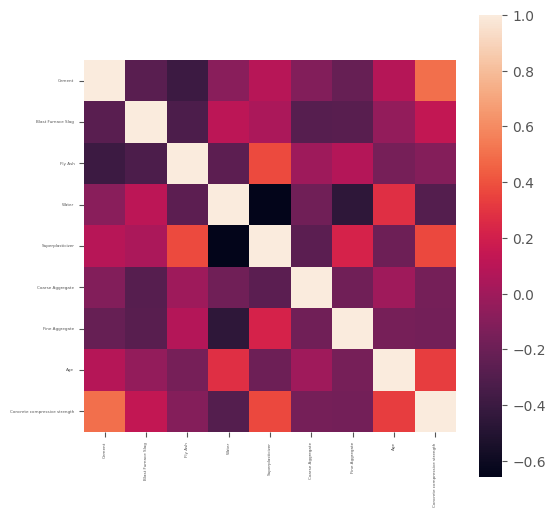

In [14]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (6,6))

sns.heatmap(
    corr_matrix,
    square = True,
    ax = ax)

ax.tick_params(labelsize = 3)

In [15]:
# Division de los datos
# 20% EN EL TEST 43
# 80% EN EL TRAIN 172

# Separar variables independientes (X) y dependiente (y)
X = datos[variables_independientes]
y = datos[variable_dependiente]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y.values.reshape(-1,1),
    test_size = 0.2,
    random_state = 42,
    shuffle = True)

print(f"Dimensiones de Entrenamiento: {X_train.shape}")
print(f"Dimensiones de Prueba: {X_test.shape}")

Dimensiones de Entrenamiento: (824, 8)
Dimensiones de Prueba: (206, 8)


## Regresión Lineal (OLS)

In [16]:
# Crear y entrenar el modelo

modelo__ols = LinearRegression()
modelo__ols.fit(X = X_train, y = y_train)

LinearRegression()

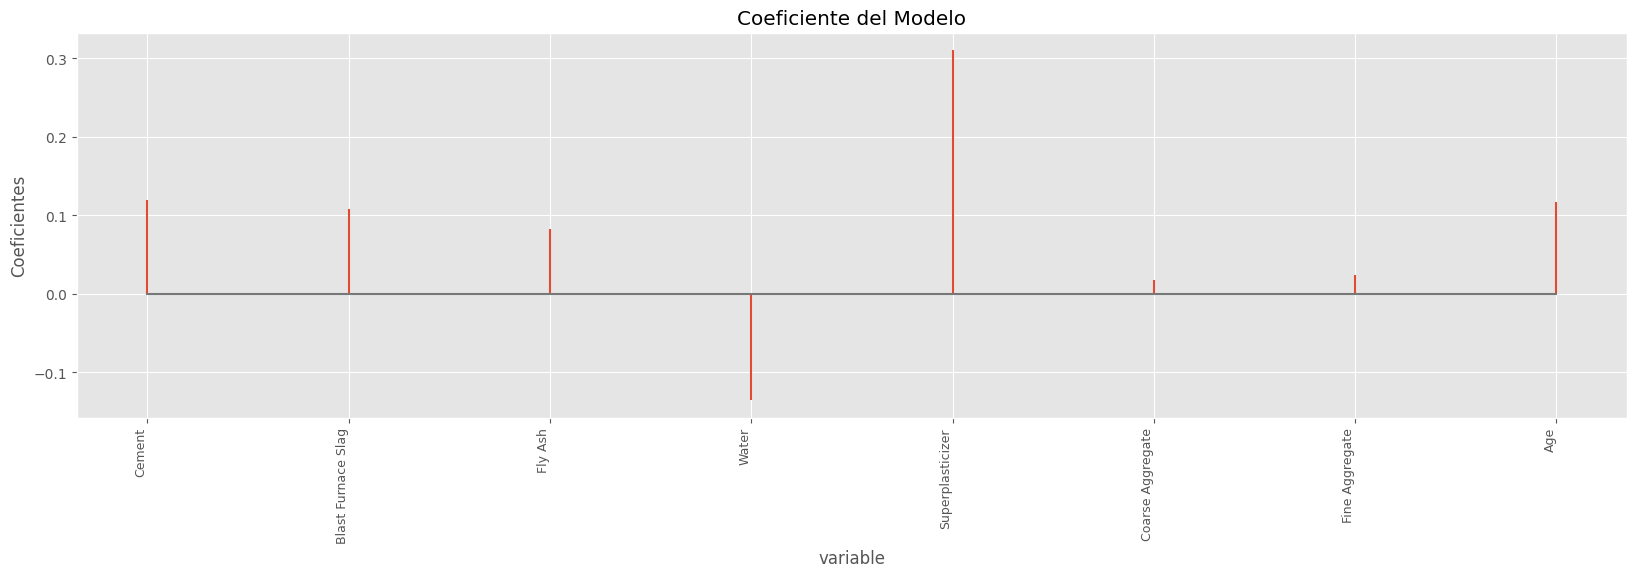

In [17]:
# Coeficientes del modelo

df_coeficientes = pd.DataFrame(
    {'predictor':X_train.columns,
     'coef': modelo__ols.coef_.flatten()})

fig, ax = plt.subplots(figsize =(20,5))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation = 90, ha = 'right', size = 9)
ax.set_ylabel('Coeficientes')
ax.set_xlabel('variable')
ax.set_title('Coeficiente del Modelo')
plt.show()

In [18]:
# Predicciones del test

predicciones = modelo__ols.predict(X= X_test)
predicciones = predicciones.flatten()
predicciones[:10]

array([59.65804162, 52.0412113 , 63.53513339, 51.57545676, 17.22001733,
       39.86561321, 26.6982471 , 44.73648869, 29.36619785, 38.18612542])

In [19]:
r2_ols = r2_score(
    y_true  = y_test,
    y_pred = predicciones)

print(f'El coeficiente determinacion del test es: {r2_ols}')

El coeficiente determinacion del test es: 0.627553179231485


## Ridge

In [20]:
modelo__ridge = RidgeCV(
    alphas = np.logspace(0.1,1.0,200),
    fit_intercept= True,
    store_cv_results= True)

_ = modelo__ridge.fit(X=X_train, y = y_train)

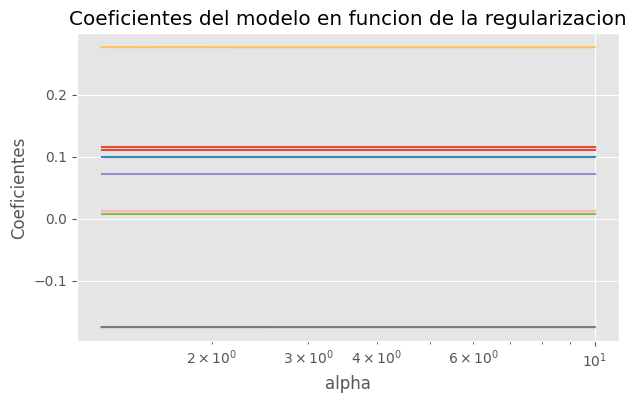

In [21]:
# Evolucion de los coeficientes en funcion al alpha

alphas  = modelo__ridge.alphas

coefs =  []

for alpha in alphas:
  modelo_temp = Ridge(alpha = alpha, fit_intercept=False)
  modelo_temp.fit(X_train, y_train)
  coefs.append(modelo_temp.coef_.flatten())


fig, ax = plt.subplots(figsize =(7,4))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_title('Coeficientes del modelo en funcion de la regularizacion')
ax.set_xlabel('alpha')
ax.set_ylabel('Coeficientes')
plt.axis('tight')
plt.show()

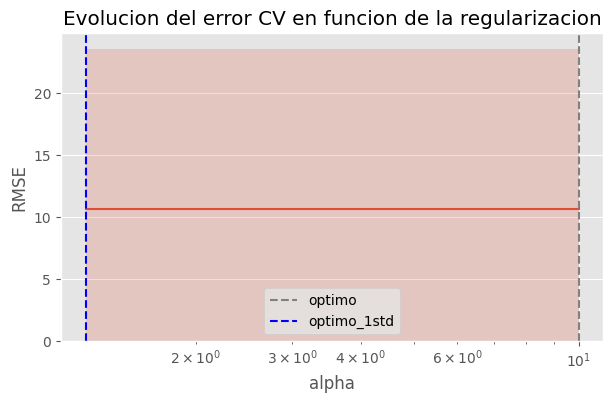

In [22]:
# Evolucion del error en funcion de alpha
#modelo.cv_values_ almacenar el mse para cada de valor de alpha. Tiene dimensiones (n_samples, n_targets, n_alphas)

mse_cv = modelo__ridge.cv_results_.reshape((-1,200)).mean(axis = 0)
mse_sd = modelo__ridge.cv_results_.reshape((-1,200)).std(axis = 0)

# Se aplica la raiz cuadrada para pasar de mse a rmse
rmse_cv = np.sqrt(mse_cv)
rmse_sd = np.sqrt(mse_sd)

# Se identifica el optimo y el optimo + 1std

min_rmse = np.min(rmse_cv)
sd_min_rmse= rmse_sd[np.argmin(rmse_cv)]
min_rsme_1std = np.max(rmse_cv[rmse_cv <= min_rmse + sd_min_rmse])
optimo = modelo__ridge.alphas[np.argmin(rmse_cv)]
optimo_1std = modelo__ridge.alphas[rmse_cv == min_rsme_1std]

# Grafico del error +- 1 desviacion estandar

fig,ax = plt.subplots(figsize = (7,4))
ax.plot(modelo__ridge.alphas, rmse_cv)
ax.fill_between(
    modelo__ridge.alphas,
    rmse_cv + rmse_sd,
    rmse_cv - rmse_sd,
    alpha = 0.2)

ax.axvline(x = optimo,
           c = 'gray',
           linestyle = '--',
           label = 'optimo')

ax.axvline(
    x = optimo_1std,
    c = 'blue',
    linestyle = '--',
    label = 'optimo_1std')

ax.set_xscale('log')
ax.set_ylim([0,None])
ax.set_title('Evolucion del error CV en funcion de la regularizacion')
ax.set_xlabel('alpha')
ax.set_ylabel('RMSE')
plt.legend()
plt.show()


In [23]:
# Mejor parametro encontrado

print(f'Mejor valor de alpha encontrado: {modelo__ridge.alpha_}')

Mejor valor de alpha encontrado: 10.0


Text(0.5, 1.0, 'Coeficientes del modelo')

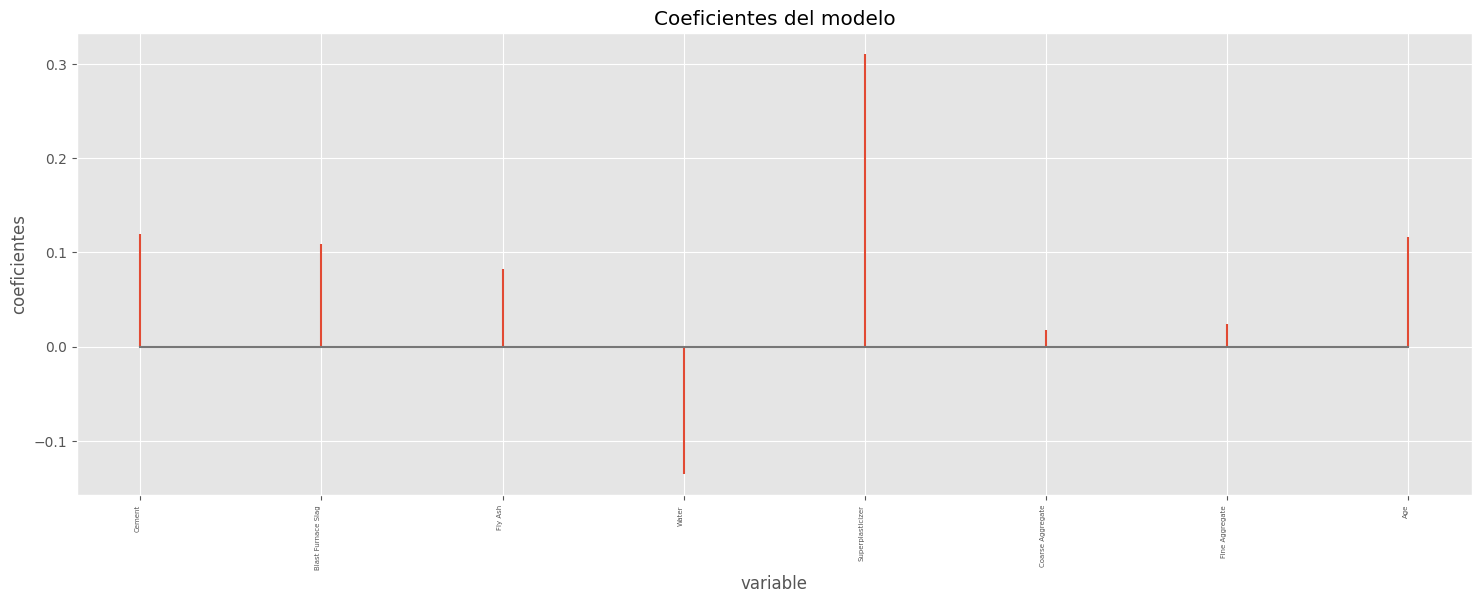

In [24]:
# Coeficientes del modelo

df_coeficientes = pd.DataFrame(
    {'predictor':X_train.columns,
     'coef':modelo__ridge.coef_.flatten()})

fig, ax = plt.subplots(figsize = (18,6))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt = ' ')
plt.xticks(rotation = 90, ha = 'right' , size = 5)
ax.set_ylabel('coeficientes')
ax.set_xlabel('variable')
ax.set_title('Coeficientes del modelo')

In [25]:
# Predicciones del Test

predicciones = modelo__ridge.predict(X = X_test)
predicciones = predicciones.flatten()
predicciones[:10]

array([59.65763059, 52.04073525, 63.53285605, 51.57498171, 17.2199612 ,
       39.86610625, 26.69863667, 44.73614687, 29.36569633, 38.18721596])

In [26]:
## Error del test del modelo

r2_ridge = r2_score(
    y_true  = y_test,
    y_pred = predicciones)

print(f'El coeficiente determinacion del test es: {r2_ridge}')

mse_ridge = mean_squared_error(
    y_true = y_test,
    y_pred = predicciones)


rmse_ridge = np.sqrt(mse_ridge)

print(f'El error (rmse) del test es: {rmse_ridge}')

El coeficiente determinacion del test es: 0.6275549031386954
El error (rmse) del test es: 9.79645322961584


## Lasso

In [27]:
# Crear y entrenar el modelo (con busqueda por CV del valor optimo de aplha)

# Por defecto el metodo RidgeCV utliza para probar el modelo el mean squared error

modelo__lasso = LassoCV(
    alphas = np.logspace(0.1,1.0,200),
    cv= 10)

_ = modelo__lasso.fit(X= X_train, y =y_train)

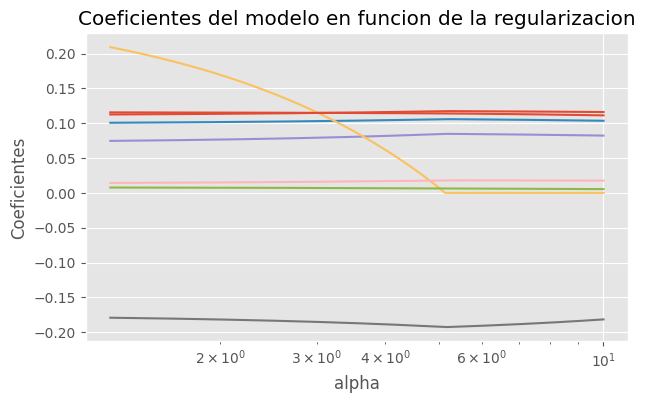

In [28]:
# Evolucion de los coeficientes en funcion al alpha

alphas = modelo__lasso.alphas

coefs =[]

for alpha in alphas:
  modelo_temp = Lasso(alpha= alpha, fit_intercept= False)
  modelo_temp.fit(X_train, y_train)
  coefs.append(modelo_temp.coef_.flatten())

fig, ax = plt.subplots(figsize = (7, 4))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_ylim([-15,None])
ax.set_ylabel('Coeficientes')
ax.set_xlabel('alpha')
ax.set_title('Coeficientes del modelo en funcion de la regularizacion')
plt.axis('tight')
plt.show()

Text(0.5, 1.0, 'Predictores incluidos en funcion de la regularizacion')

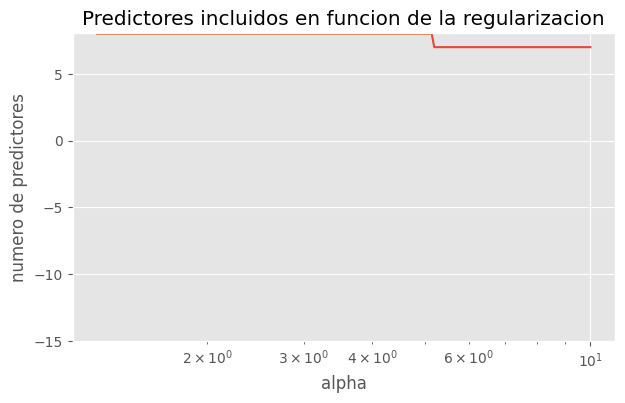

In [29]:
# Numero de predictores incluidos (coeficientes != 0) en funcion de alpha

alphas = modelo__lasso.alphas_
n_predictores = []

for alpha in alphas:
  modelo_temp = Lasso(alpha = alpha, fit_intercept=False)
  modelo_temp.fit(X_train, y_train)
  coef_no_cero = np.sum(modelo_temp.coef_.flatten()!= 0)
  n_predictores.append(coef_no_cero)

fig,ax = plt.subplots(figsize = (7, 4))
ax.plot(alphas, n_predictores)
ax.set_xscale('log')
ax.set_ylim([-15, None])
ax.set_xlabel('alpha')
ax.set_ylabel('numero de predictores')
ax.set_title('Predictores incluidos en funcion de la regularizacion')

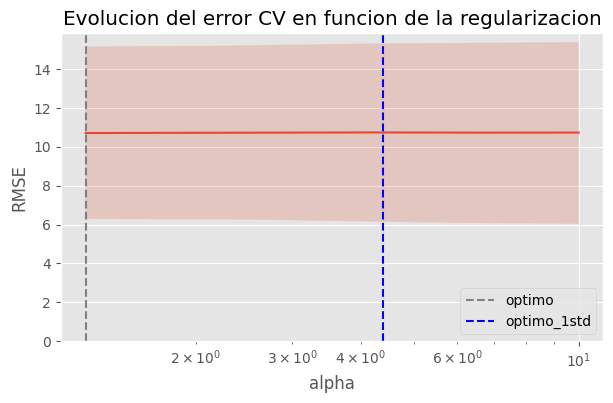

In [30]:
# Evolucion del error en funcion de alpha
#modelo.mse_path_ almacenar el mse para cada de valor de alpha. Tiene dimensiones (n_samples, n_targets, n_alphas)

mse_cv = modelo__lasso.mse_path_.mean(axis = 1)
mse_sd = modelo__lasso.mse_path_.std(axis = 1)

# Se aplica la raiz cuadrada para pasar de mse a rmse
rmse_cv = np.sqrt(mse_cv)
rmse_sd = np.sqrt(mse_sd)

# Se identifica el optimo y el optimo + 1std

min_rmse = np.min(rmse_cv)
sd_min_rmse= rmse_sd[np.argmin(rmse_cv)]
min_rsme_1std = np.max(rmse_cv[rmse_cv <= min_rmse + sd_min_rmse])
optimo = modelo__lasso.alphas_[np.argmin(rmse_cv)]
optimo_1std = modelo__lasso.alphas_[rmse_cv == min_rsme_1std]

# Grafico del error +- 1 desviacion estandar

fig,ax = plt.subplots(figsize = (7,4))
ax.plot(modelo__lasso.alphas_, rmse_cv)
ax.fill_between(
    modelo__lasso.alphas,
    rmse_cv + rmse_sd,
    rmse_cv - rmse_sd,
    alpha = 0.2)

ax.axvline(x = optimo,
           c = 'gray',
           linestyle = '--',
           label = 'optimo')

ax.axvline(
    x = optimo_1std,
    c = 'blue',
    linestyle = '--',
    label = 'optimo_1std')

ax.set_xscale('log')
ax.set_ylim([0,None])
ax.set_title('Evolucion del error CV en funcion de la regularizacion')
ax.set_xlabel('alpha')
ax.set_ylabel('RMSE')
plt.legend()
plt.show()

In [31]:
# Mejor valor alpha

print(f'Mejor valor de alpha encontrado: {modelo__lasso.alpha_}')

Mejor valor de alpha encontrado: 1.2589254117941673


In [32]:
# Se identifica el optimo y el optimo + 1std

min_rmse = np.min(rmse_cv)
sd_min_rmse= rmse_sd[np.argmin(rmse_cv)]
min_rsme_1std = np.max(rmse_cv[rmse_cv <= min_rmse + sd_min_rmse])
optimo = modelo__lasso.alphas_[np.argmin(rmse_cv)]
optimo_1std = modelo__lasso.alphas_[rmse_cv == min_rsme_1std]

print(f'Mejor valor de alpha encontrado: {optimo}')

Mejor valor de alpha encontrado: 1.2589254117941673


In [33]:
#Mejor Modelo alpha optimo + 1std

modelo = Lasso(alpha = 0.0000004552935074866957)
modelo.fit(X_train, y_train)

Lasso(alpha=4.552935074866957e-07)

In [34]:
# Coeficientes

df_coeficientes = pd.DataFrame(
    {'predictor':X_train.columns,
     'coef':modelo.coef_.flatten()})


df_coeficientes[df_coeficientes.coef != 0]

,predictor,coef
0,Cement,0.118994
1,Blast Furnace Slag,0.108536
2,Fly Ash,0.082152
3,Water,-0.135276
4,Superplasticizer,0.310570
5,Coarse Aggregate,0.017867
6,Fine Aggregate,0.024100
7,Age,0.116439


Text(0.5, 1.0, 'Coeficientes del modelo')

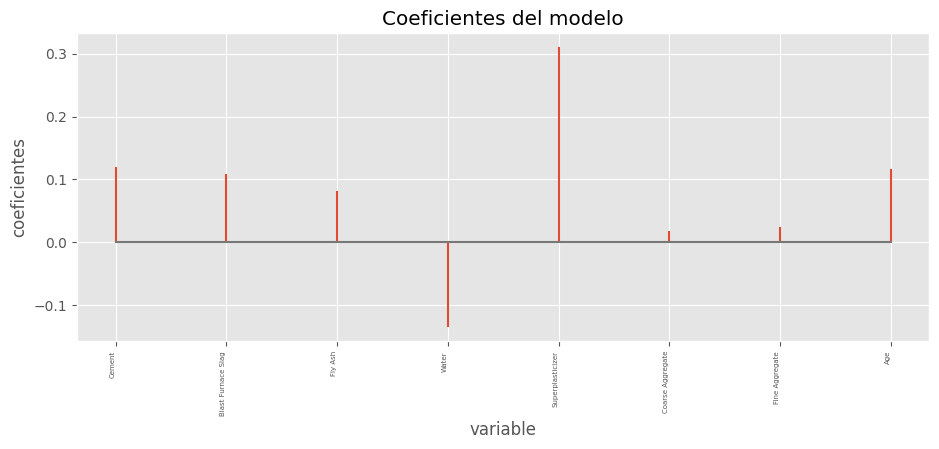

In [35]:
fig, ax = plt.subplots(figsize = (11,4))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt = ' ')
plt.xticks(rotation = 90, ha = 'right' , size = 5)
ax.set_ylabel('coeficientes')
ax.set_xlabel('variable')
ax.set_title('Coeficientes del modelo')

In [36]:
# Predicciones del Test

predicciones = modelo.predict(X = X_test)
predicciones = predicciones.flatten()
predicciones[:10]

array([59.65804158, 52.04121122, 63.53513312, 51.57545668, 17.22001735,
       39.86561328, 26.69824716, 44.73648861, 29.36619777, 38.18612557])

In [37]:
## Error del test del modelo

r2_lasso = r2_score(
    y_true  = y_test,
    y_pred = predicciones)

print(f'El coeficiente determinacion del test es: {r2_lasso}')

## Error del test del modelo

mse_lasso = mean_squared_error(
    y_true = y_test,
    y_pred = predicciones)

rmse_lasso = np.sqrt(mse_lasso)

print(f'El error (rmse) del test es: {rmse_lasso}')

El coeficiente determinacion del test es: 0.6275531793425497
El error (rmse) del test es: 9.79647590016369


## Parte 4. Evaluación de modelos (20 puntos)

In [38]:
# Predicciones sobre los datos de prueba
pred_ols = modelo__ols.predict(X_test).flatten()
pred_ridge = modelo__ridge.predict(X_test).flatten()
pred_lasso = modelo__lasso.predict(X_test).flatten()

# Calcular el coeficiente de determinación (R²)
r2_ols = r2_score(y_test, pred_ols)
r2_ridge = r2_score(y_test, pred_ridge)
r2_lasso = r2_score(y_test, pred_lasso)

# Calcular la raiz del error cuadrático medio (RMSE)
rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
rmse_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))
rmse_lasso = np.sqrt(mean_squared_error(y_test, pred_lasso))

# Generar Tabla Comparativa de Resultados
resultados_comparativos = pd.DataFrame({
    'Modelo': ['Minimos Cuadrados (OLS)', 'Ridge', 'Lasso'],
    'R²': [r2_ols, r2_ridge, r2_lasso],
    'RMSE': [rmse_ols, rmse_ridge, rmse_lasso]})

# Visualización de la tabla de Resultados
resultados_comparativos


,Modelo,R²,RMSE
0,Minimos Cuadrados (OLS),0.627553,9.796476
1,Ridge,0.627555,9.796453
2,Lasso,0.627545,9.796586


> * ### Mejor modelo de rendimiento predictivo basado en R²: ***Mínimos Cuadrados (OLS)***
> * ### Mejor modelo de rendimiento predictivo basado en RMSE: ***Ridge***

## Parte 5. Conclusiones (10 puntos)

Responder con sus propias palabras:

1. ¿Cuál de los tres modelos obtuvo el mejor resultado y por qué?
> El modelo de Ridge fué el que obtuvo el mejor resultado, ya que presenta el menor error en el conjunto de prueba (RMSE), y el mayor coeficiente de determinación (R²).  
Ridge es más efectivo porque reduce el impacto de la multicolinealidad moderada como la fuerte correlación negativa entre el agua y el superplastificante.

2. ¿Qué significa el valor de R² obtenido por el mejor modelo?
> Significa que aproximadamente el 62.76% de la variabilidad observada en la resistencia a la compresión del concreto puede ser predicha por las variables independientes.
3. ¿Qué representa el RMSE en el contexto de la resistencia del concreto?
> Representa la desviación o error promedio de las predicciones del modelo respecto a los valores reales de resistencia.
4. ¿Qué diferencias encontró entre OLS, Ridge y Lasso?
> * OLS: Utiliza todos los predictores de manera directa. Es sensible a la colinealidad y puede presentar alta varianza si hay variables redundantes.
> * Ridge: Mantiene todos los predictores en el modelo pero disminuye su magnitud. Es excelente para mitigar la multicolinealidad.
> * Lasso: Tiene la propiedad de realizar selección de variables. En este caso práctico, su comportamiento final fue muy similar a OLS.

5. ¿Considera que estos modelos podrían resultar útiles para la empresa? Justifique su respuesta.
> Pueden ser muy útiles como herramienta de apoyo y optimización en fase de diseño de mezclas.
Este modelo matemático permite simular multiples combinaciones, descartando composiciones débiles antes de prepararlas físicamente.
